# 3D evaluation: monocular vs sensor point clouds

The same object, two point clouds: one back-projected from **sensor
depth** (`depth_bfx`, the reference) and one from **monocular depth** (Depth
Anything V2 Small, aligned per-image with `lstsq_disp` — notebook 06). Both go
through the identical cloud pipeline (`utils/pointcloud.py`, notebook 05 —
mask refinement, back-projection, voxel + SOR cleaning), and the question is how much
3D geometry is lost by replacing the depth sensor with a single RGB camera:

1. **Chamfer distance** between the paired clouds (overall shape fidelity);
2. **deviation of object characteristics** — centroid, distance to camera,
   OBB dimensions, OBB/convex-hull volume (the quantities chapter 3 reports);
3. **error dependence** on distance, object size, class and sensor.

Inputs: aligned monocular maps of the full std10 test split stored by
notebook 06 (`outputs/depth_mono/maps/*.npy`), GT masks.

In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d
from pycocotools.coco import COCO

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd
import utils.pointcloud as pc

print("Open3D:", o3d.__version__)

Open3D: 0.19.0


In [2]:
DATASET_ROOT = Path("/Users/polina_sushko/My_work/University/ВКР/SUNRGBD")
SPLIT_DIR    = Path("outputs/splits")            # std10 config
MAP_DIR      = Path("outputs/depth_mono/maps")   # aligned monocular maps (notebook 06)
OUT_DIR      = Path("outputs/eval3d")

# cloud pipeline constants and functions are owned by utils/pointcloud.py
MIN_POINTS = pc.MIN_POINTS   # per cloud; a pair is kept only if BOTH clouds pass
print(f"cloud pipeline: voxel {pc.VOXEL_SIZE} m, SOR ({pc.SOR_NEIGHBORS}, {pc.SOR_STD_RATIO}), "
      f"min points {MIN_POINTS}; refinement: erode {pc.ERODE_PX} px, edge window "
      f"{pc.EDGE_WINDOW} px, MAD k = {pc.DEPTH_MAD_K}")

SENSOR_COLOR = "#2a78d6"     # blue   = sensor reference
MONO_COLOR   = "#eb6834"     # orange = monocular estimate

OUT_DIR.mkdir(parents=True, exist_ok=True)
coco = COCO(str(SPLIT_DIR / "instances_test.json"))
cat_name = {c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())}

map_ids = sorted(int(p.stem) for p in MAP_DIR.glob("*.npy"))
print(f"Aligned monocular maps: {len(map_ids)} "
      f"(test image ids {map_ids[0]}..{map_ids[-1]})")


cloud pipeline: voxel 0.02 m, SOR (20, 2.0), min points 100; refinement: erode 2 px, edge window 5 px, MAD k = 3.0
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Aligned monocular maps: 1325 (test image ids 1..10326)


---
## Evaluation protocol

**Paired clouds on the common reliable-pixel set.** For every GT instance mask
the back-projection uses only the pixels that `pc.refine_mask()` accepts in
*both* maps: valid depth (sensor in (0.3, 8) m, monocular > 0 after alignment),
outside the 2-px mask border, off depth discontinuities and not a per-object
depth outlier — in each map separately, then intersected. Both clouds are
therefore built from the same pixel footprint, and every difference between
them is caused by the depth *values*, not by coverage. Coverage itself is
tracked separately (`joint_valid_frac` = accepted pixels / mask pixels).

**Per-image alignment = the upper bound.** The stored maps use per-image
`lstsq_disp` (an oracle that needs the sensor map of the same image), so the
numbers below characterise the *best case* of monocular geometry. The
sensor-free configurations (global alignment, metric models) are evaluated
end-to-end in notebook 08.

Metrics per object: symmetric Chamfer-L1 distance (mean over both directions,
cm), centroid offset (cm), signed distance-to-camera error (m), and signed
percentage errors of sorted OBB extents and OBB/convex-hull volumes.


In [3]:
def load_pair(img_info: dict):
    """RGB, sensor depth, aligned monocular depth and intrinsics for one image."""
    rgb   = sd.read_rgb(DATASET_ROOT / img_info["file_name"])
    d_sen = sd.read_depth(DATASET_ROOT / img_info["depth_file"])
    d_mon = np.load(MAP_DIR / f"{img_info['id']}.npy").astype(np.float32)
    intr  = sd.Intrinsics(fx=img_info["fx"], fy=img_info["fy"],
                          cx=img_info["cx"], cy=img_info["cy"])
    return rgb, d_sen, d_mon, intr


PAIRED_KEYS = ["obb_extent_1", "obb_extent_2", "obb_extent_3",
               "obb_volume_m3", "hull_volume_m3"]


def process_image(img_id: int, keep_clouds: bool = False):
    """Paired per-object rows (sensor vs monocular clouds) for one test image."""
    info = coco.loadImgs(img_id)[0]
    anns = coco.loadAnns(coco.getAnnIds(imgIds=img_id, iscrowd=False))
    rgb, d_sen, d_mon, intr = load_pair(info)
    rows, clouds = [], []
    for ann in anns:
        mask = coco.annToMask(ann).astype(bool)
        # pixels accepted by the refinement in BOTH maps -> identical footprint
        pair_mask = pc.refine_mask(mask, d_sen) & pc.refine_mask(mask, d_mon)
        pcd_s = pc.build_cloud(d_sen, intr, pair_mask, rgb, refine=False)
        pcd_m = pc.build_cloud(d_mon, intr, pair_mask, rgb, refine=False)
        if len(pcd_s.points) < MIN_POINTS or len(pcd_m.points) < MIN_POINTS:
            continue
        ms, mm = pc.object_3d_metrics(pcd_s), pc.object_3d_metrics(pcd_m)
        row = {"image_id": img_id, "ann_id": ann["id"],
               "class": cat_name[ann["category_id"]], "sensor": info["sensor"],
               "mask_area_px": ann["area"],
               "joint_valid_frac": float(pair_mask.sum() / max(mask.sum(), 1)),
               "n_points_sensor": ms["n_points"], "n_points_mono": mm["n_points"],
               "dist_sensor_m": ms["dist_to_camera_m"],
               "dist_mono_m": mm["dist_to_camera_m"],
               "dist_err_m": mm["dist_to_camera_m"] - ms["dist_to_camera_m"],
               "centroid_offset_cm": 100.0 * float(
                   np.linalg.norm(mm["centroid"] - ms["centroid"])),
               "chamfer_cm": pc.chamfer_cm(pcd_s, pcd_m)}
        for k in PAIRED_KEYS:
            row[f"{k}_sensor"] = ms[k]
            row[f"{k}_mono"] = mm[k]
            row[f"{k}_pct_err"] = pc.pct_err(mm[k], ms[k])
        rows.append(row)
        if keep_clouds:
            clouds.append((row, pcd_s, pcd_m))
    return info, rows, clouds


---
## Single-scene walkthrough

One test scene end to end: both depth maps, their pixel-wise difference, and the
paired instance clouds overlaid in 3D — the visual intuition for what a Chamfer
distance of a few centimetres actually looks like.

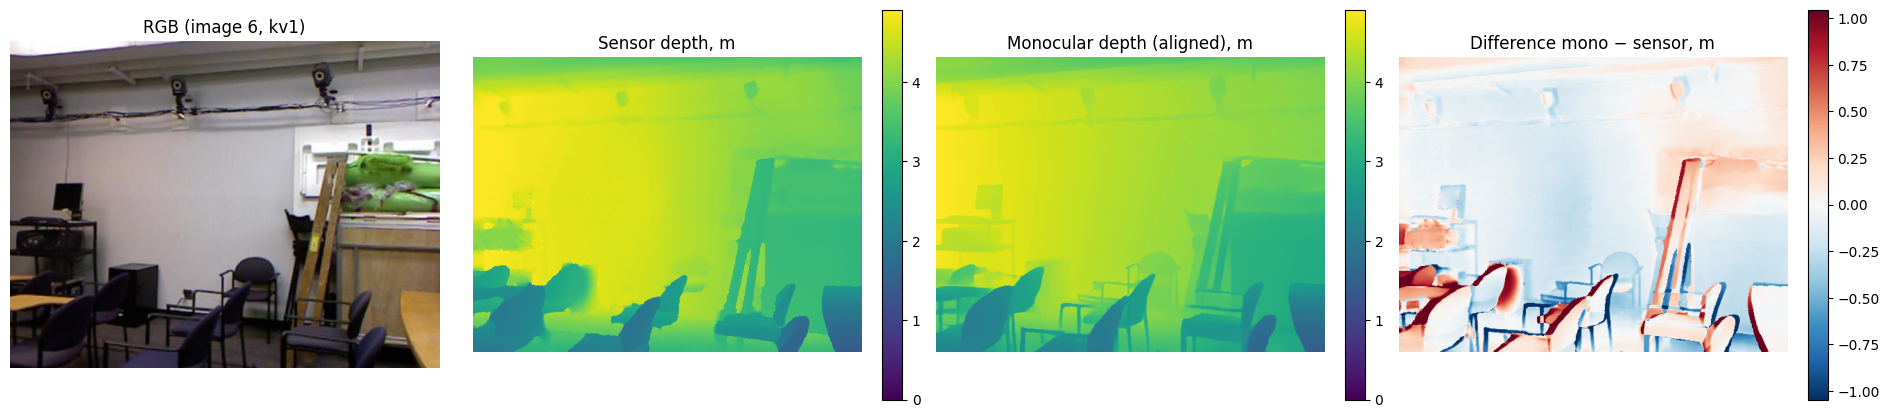

,class,chamfer_cm,centroid_offset_cm,dist_err_m,obb_volume_m3_pct_err,hull_volume_m3_pct_err
0,chair,3.60,6.96,-0.07,-31.00,-3.33
1,chair,5.33,7.81,0.08,29.96,58.41
2,chair,12.27,18.99,-0.19,-58.81,-58.49
3,table,0.79,4.70,0.05,141.57,70.05


In [4]:
sample_id = next(
    img_id for img_id in map_ids
    if len(process_image(img_id)[1]) >= 3
    and len({r["class"] for r in process_image(img_id)[1]}) >= 2)
sample_info, sample_rows, sample_clouds = process_image(sample_id, keep_clouds=True)
rgb, d_sen, d_mon, intr = load_pair(sample_info)
joint = pc.usable_depth(d_sen) & pc.usable_depth(d_mon)

diff = np.where(joint, d_mon - d_sen, np.nan)
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
axes[0].imshow(rgb); axes[0].set_title(f"RGB (image {sample_id}, {sample_info['sensor']})")
vmax = np.nanpercentile(d_sen[joint], 99)
im1 = axes[1].imshow(np.where(joint, d_sen, np.nan), cmap="viridis", vmin=0, vmax=vmax)
axes[1].set_title("Sensor depth, m"); fig.colorbar(im1, ax=axes[1], fraction=0.046)
im2 = axes[2].imshow(np.where(joint, d_mon, np.nan), cmap="viridis", vmin=0, vmax=vmax)
axes[2].set_title("Monocular depth (aligned), m"); fig.colorbar(im2, ax=axes[2], fraction=0.046)
lim = np.nanpercentile(np.abs(diff), 98)
im3 = axes[3].imshow(diff, cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[3].set_title("Difference mono − sensor, m"); fig.colorbar(im3, ax=axes[3], fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "sample_depth_pair.png", dpi=150, bbox_inches="tight")
plt.show()

sample_df = pd.DataFrame(sample_rows)
sample_df[["class", "chamfer_cm", "centroid_offset_cm", "dist_err_m",
           "obb_volume_m3_pct_err", "hull_volume_m3_pct_err"]].round(2)

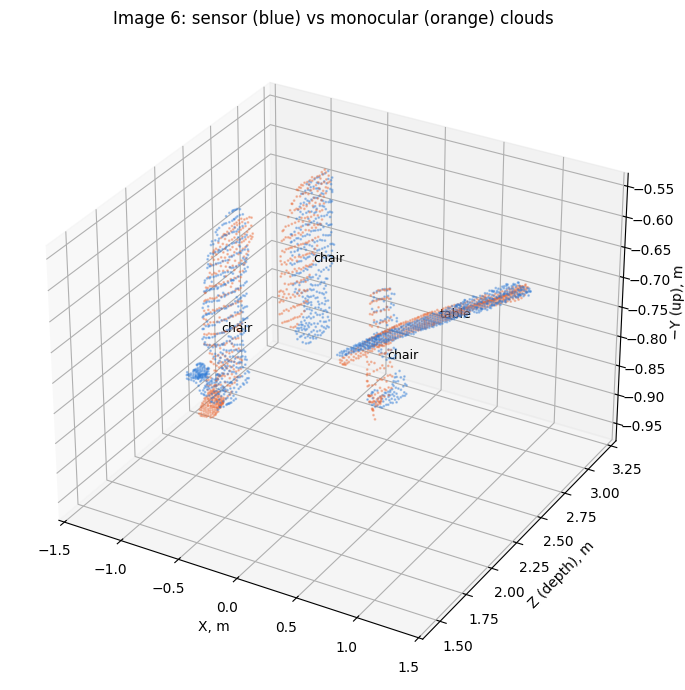

In [5]:
# paired instance clouds in 3D: sensor (blue) vs monocular (orange), Y flipped for display
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")
for row, pcd_s, pcd_m in sample_clouds:
    for pcd, color in ((pcd_s, SENSOR_COLOR), (pcd_m, MONO_COLOR)):
        pts = np.asarray(pcd.points)
        ax.scatter(pts[:, 0], pts[:, 2], -pts[:, 1], s=1, c=color, alpha=0.35)
for row, pcd_s, _ in sample_clouds:
    cen = np.asarray(pcd_s.points).mean(axis=0)
    ax.text(cen[0], cen[2], -cen[1], row["class"], fontsize=9)
ax.set_xlabel("X, m"); ax.set_ylabel("Z (depth), m"); ax.set_zlabel("−Y (up), m")
ax.set_title(f"Image {sample_id}: sensor (blue) vs monocular (orange) clouds")
plt.tight_layout()
plt.savefig(OUT_DIR / "sample_clouds_3d.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Batch evaluation over the full test split

Every instance on every image with a stored monocular map. The resulting table
is the data source for all chapter 3.4 statistics.

In [6]:
all_rows = []
t0 = time.time()
for n, img_id in enumerate(map_ids, 1):
    _, rows, _ = process_image(img_id)
    all_rows.extend(rows)
    if n % 20 == 0 or n == len(map_ids):
        print(f"  {n}/{len(map_ids)} images, {len(all_rows)} objects "
              f"({n / (time.time() - t0):.2f} img/s)", end="\r")
print()

df = pd.DataFrame(all_rows)
df.to_csv(OUT_DIR / "object_metrics_mono_vs_sensor.csv", index=False)
print(f"Paired objects: {len(df)} on {df.image_id.nunique()} images "
      f"({time.time() - t0:.0f} s)")
print(f"Median joint-valid coverage of masks: {df.joint_valid_frac.median():.3f}")

  1325/1325 images, 4172 objects (8.49 img/s)
Paired objects: 4172 on 1303 images (156 s)
Median joint-valid coverage of masks: 0.708


---
## Overall summary

Signed statistics show *bias* (does monocular depth systematically inflate or
shrink objects?), absolute statistics show *magnitude* of the error a downstream
user should expect.

In [7]:
KEY_COLS = ["chamfer_cm", "centroid_offset_cm", "dist_err_m",
            "obb_extent_1_pct_err", "obb_extent_2_pct_err", "obb_extent_3_pct_err",
            "obb_volume_m3_pct_err", "hull_volume_m3_pct_err"]

summary = pd.DataFrame({
    "median_signed": df[KEY_COLS].median(),
    "mean_signed":   df[KEY_COLS].mean(),
    "median_abs":    df[KEY_COLS].abs().median(),
    "mean_abs":      df[KEY_COLS].abs().mean(),
}).round(2)
summary.to_csv(OUT_DIR / "summary_overall.csv")
summary

,median_signed,mean_signed,median_abs,mean_abs
chamfer_cm,8.63,25.81,8.63,25.81
centroid_offset_cm,13.32,33.67,13.32,33.67
dist_err_m,-0.05,-0.22,0.13,0.33
obb_extent_1_pct_err,-6.10,-7.23,11.86,17.92
obb_extent_2_pct_err,-7.71,-8.54,14.29,19.99
obb_extent_3_pct_err,-16.01,-13.20,24.89,34.29
obb_volume_m3_pct_err,-30.25,-18.03,42.11,51.33
hull_volume_m3_pct_err,-32.56,-26.47,40.41,47.12


---
## Error breakdown: distance, size, class, sensor

Where monocular 3D degrades — the material for the discussion in 3.4. Absolute
percentage errors are used for grouping (bias cancels out in group means
otherwise).

In [8]:
BRK_COLS = ["chamfer_cm", "centroid_offset_cm"]
ABS_COLS = ["obb_volume_m3_pct_err", "hull_volume_m3_pct_err", "obb_extent_1_pct_err"]

def breakdown(frame: pd.DataFrame, by) -> pd.DataFrame:
    g = frame.groupby(by, observed=True)
    out = g[BRK_COLS].median()
    out[[f"abs_{c}" for c in ABS_COLS]] = g[ABS_COLS].apply(lambda x: x.abs().median())
    out["n_objects"] = g.size()
    return out.round(2)

df["dist_bin"] = pd.cut(df.dist_sensor_m, [0, 1.5, 2.5, 3.5, 5, 8],
                        labels=["<1.5 m", "1.5–2.5 m", "2.5–3.5 m", "3.5–5 m", ">5 m"])
df["size_bin"] = pd.qcut(df.mask_area_px, 3, labels=["small", "medium", "large"])

by_distance = breakdown(df, "dist_bin")
by_size     = breakdown(df, "size_bin")
by_class    = breakdown(df, "class").sort_values("chamfer_cm")
by_sensor   = breakdown(df, "sensor")

for name, table in [("distance", by_distance), ("size", by_size),
                    ("class", by_class), ("sensor", by_sensor)]:
    table.to_csv(OUT_DIR / f"breakdown_{name}.csv")

print("By distance to camera:"); display(by_distance)
print("By mask size (area terciles):"); display(by_size)
print("By sensor:"); display(by_sensor)

By distance to camera:


,chamfer_cm,centroid_offset_cm,abs_obb_volume_m3_pct_err,abs_hull_volume_m3_pct_err,abs_obb_extent_1_pct_err,n_objects
dist_bin,,,,,,
<1.5 m,4.13,5.93,32.24,30.95,8.84,471
1.5–2.5 m,6.00,9.06,33.68,31.92,8.41,1738
2.5–3.5 m,12.76,19.68,45.65,43.66,13.25,1019
3.5–5 m,28.36,41.38,56.98,56.74,20.31,652
>5 m,102.42,127.31,75.92,75.70,30.61,268


By mask size (area terciles):


,chamfer_cm,centroid_offset_cm,abs_obb_volume_m3_pct_err,abs_hull_volume_m3_pct_err,abs_obb_extent_1_pct_err,n_objects
size_bin,,,,,,
small,18.89,28.42,57.34,54.66,18.14,1391
medium,8.18,12.79,38.68,38.73,11.51,1390
large,5.48,8.03,31.51,29.69,7.42,1391


By sensor:


,chamfer_cm,centroid_offset_cm,abs_obb_volume_m3_pct_err,abs_hull_volume_m3_pct_err,abs_obb_extent_1_pct_err,n_objects
sensor,,,,,,
kv1,7.36,11.11,39.37,34.55,9.95,537
kv2,10.34,15.99,46.11,46.40,12.14,1917
realsense,11.91,19.44,53.64,55.95,17.56,438
xtion,7.06,10.66,34.94,31.37,10.51,1280


In [9]:
print("By class (sorted by Chamfer):")
by_class

By class (sorted by Chamfer):


,chamfer_cm,centroid_offset_cm,abs_obb_volume_m3_pct_err,abs_hull_volume_m3_pct_err,abs_obb_extent_1_pct_err,n_objects
class,,,,,,
toilet,5.73,7.79,27.73,28.16,4.98,37
desk,6.48,10.79,37.22,35.77,10.46,298
table,6.50,10.65,42.25,39.70,10.54,986
bathtub,6.84,8.93,33.04,28.45,8.67,24
bed,8.39,13.50,37.07,36.46,10.29,202
chair,9.82,14.41,41.79,40.63,12.46,2148
sofa,11.47,17.96,44.44,45.61,13.38,246
nightstand,11.89,18.60,59.73,55.33,18.40,64
dresser,12.96,21.85,54.15,60.46,10.69,68


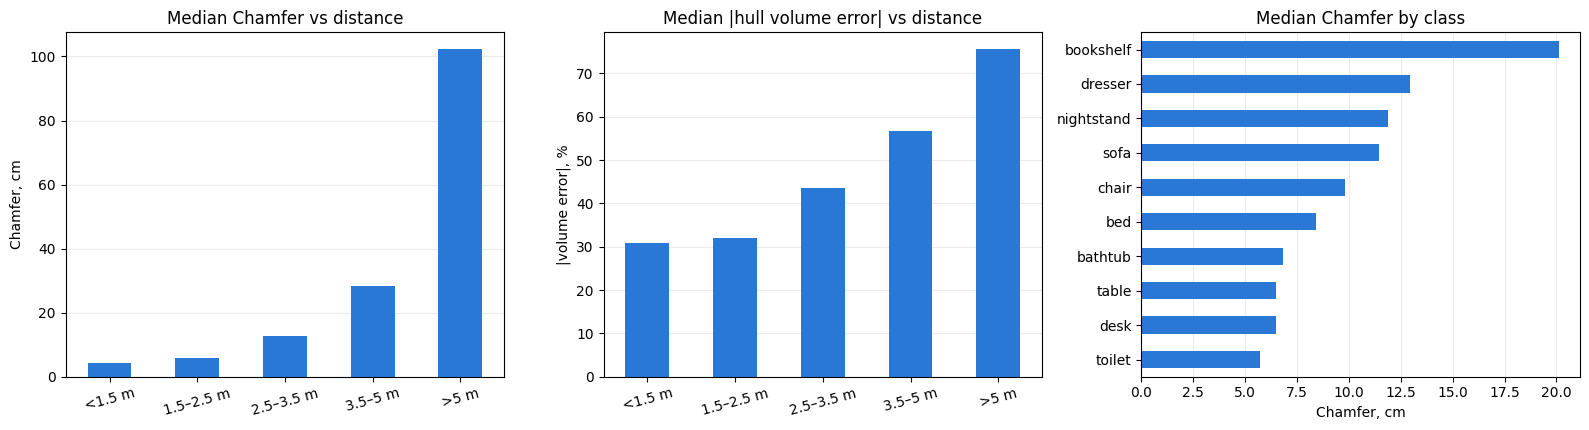

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

by_distance["chamfer_cm"].plot.bar(ax=axes[0], color=SENSOR_COLOR, rot=15)
axes[0].set_title("Median Chamfer vs distance"); axes[0].set_ylabel("Chamfer, cm")
axes[0].set_xlabel("")

by_distance["abs_hull_volume_m3_pct_err"].plot.bar(ax=axes[1], color=SENSOR_COLOR, rot=15)
axes[1].set_title("Median |hull volume error| vs distance")
axes[1].set_ylabel("|volume error|, %"); axes[1].set_xlabel("")

by_class["chamfer_cm"].plot.barh(ax=axes[2], color=SENSOR_COLOR)
axes[2].set_title("Median Chamfer by class"); axes[2].set_xlabel("Chamfer, cm")
axes[2].set_ylabel("")

for ax in axes:
    ax.grid(axis="y" if ax is not axes[2] else "x", alpha=0.25)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(OUT_DIR / "error_breakdown_3d.png", dpi=150, bbox_inches="tight")
plt.show()

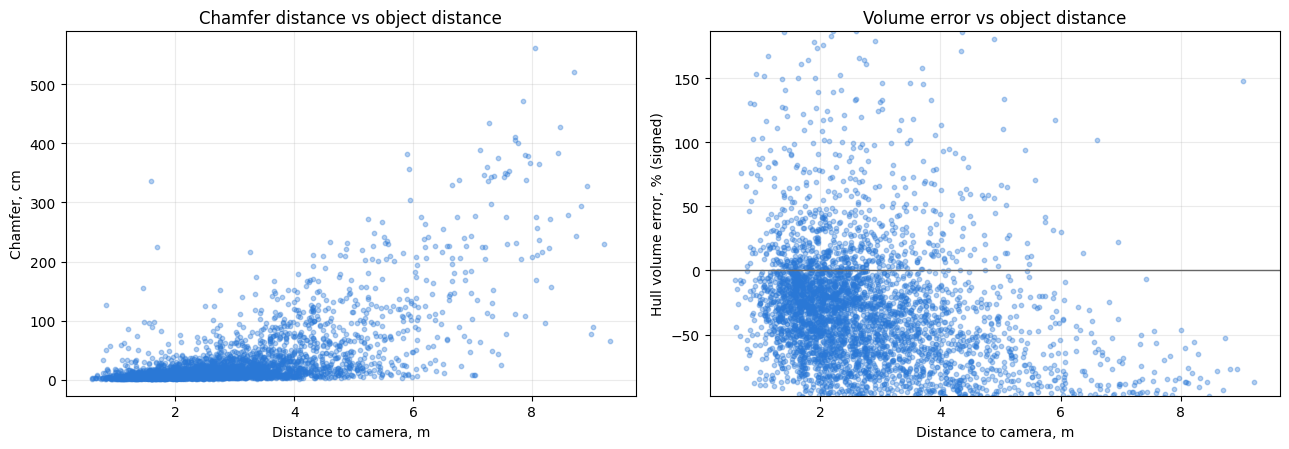

In [11]:
# per-object scatter: Chamfer and volume error vs distance to camera
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].scatter(df.dist_sensor_m, df.chamfer_cm, s=10, c=SENSOR_COLOR, alpha=0.35)
axes[0].set_xlabel("Distance to camera, m"); axes[0].set_ylabel("Chamfer, cm")
axes[0].set_title("Chamfer distance vs object distance")

axes[1].scatter(df.dist_sensor_m, df.hull_volume_m3_pct_err, s=10,
                c=SENSOR_COLOR, alpha=0.35)
axes[1].axhline(0, color="0.4", lw=1)
axes[1].set_xlabel("Distance to camera, m")
axes[1].set_ylabel("Hull volume error, % (signed)")
axes[1].set_title("Volume error vs object distance")
axes[1].set_ylim(np.nanpercentile(df.hull_volume_m3_pct_err, [1, 99]))

for ax in axes:
    ax.grid(alpha=0.25); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(OUT_DIR / "error_vs_distance_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Findings

**Overall (4172 paired objects on 1303 test images, per-image alignment = best
case; refined-mask pipeline of `utils/pointcloud.py`).** Mask refinement keeps
a median 71 % of each mask's pixels and drops 13 % of the objects of the
first-version protocol (4821 → 4172) — small or distant instances that fall
below `MIN_POINTS` once their border band and background leaks are removed.

- **Shape:** median Chamfer distance **8.6 cm** (mean 25.8 cm — a heavy tail
  from distant objects); median centroid offset 13 cm. Median signed
  distance-to-camera error is only **−0.05 m** (0.13 m absolute): monocular
  clouds put objects at nearly the correct range.
- **Refinement removed the "curtain" component of the error.** Against the
  unrefined protocol (Chamfer 10.0 cm, centroid offset 18 cm, largest-extent
  error −15 % / |23 %|) the linear-size errors halved: largest OBB extent
  −6 % signed, **12 %** absolute; the other two extents 14–25 %. The streaks
  of boundary points that used to connect an object to its background were
  the least stable part of both clouds.
- **Systematic shrinkage remains.** Signed median errors: OBB volume **−30 %**,
  convex hull volume **−33 %**, smallest OBB extent −16 %. Monocular relief is
  flatter than reality — depth variation inside an object is compressed, which
  shortens the extent along the viewing axis and collapses volumes; no mask
  filtering can fix this, it is a property of the depth values.
- **Absolute sizes are unreliable, linear sizes less so.** Median |error|:
  ~40–42 % for volumes vs 12–14 % for the two largest OBB extents.
- **Distance is the dominant error factor.** Median Chamfer grows
  4.1 → 6.0 → 12.8 → 28.4 → **102 cm** across the distance bins
  (<1.5 m … >5 m); median |hull volume error| grows 31 % → 76 %. Beyond
  ~3.5 m monocular geometry degrades quickly; beyond 5 m it is unusable.
- **Object size matters the same way:** large objects (top tercile of mask
  area) get 5.5 cm median Chamfer vs 18.9 cm for small ones.
- **Sensors rank exactly as their depth quality in notebook 06**
  (AbsRel xtion < kv1 < kv2 < realsense): median Chamfer xtion 7.1 < kv1 7.4 <
  kv2 10.3 < realsense 11.9 cm — the 3D error is driven by how well the
  monocular map matches that sensor's depth statistics, not by resolution.
- **Classes.** Compact objects seen at close range are easiest — toilet
  5.7 cm, desk 6.5, table 6.5, bathtub 6.8, bed 8.4. The worst are thin or
  cluttered structures: bookshelf 20.1 cm (volume |error| 61 %) and dresser
  13.0 — flat frontal surfaces with little internal depth relief that the
  smooth monocular prediction places at a slightly wrong slant.

**Practical conclusion.** Even in the oracle per-image regime, monocular 3D is
suitable for *approximate localisation and relative scene layout* at close
range (<3.5 m): object centroids and distances are nearly unbiased, linear
sizes are within ~12–15 %, shapes are recognisable (see the overlay above). It
is **not** suitable for measuring absolute volumes (~40 % error) and it
systematically underestimates depth extent. The sensor-free depth backends
(global alignment, metric models) are evaluated end-to-end in notebook 08.
